# DESENVOLVIMENTO DA INICIAÇÃO CIENTÍFICA 

## Contexto do Projeto 2025
Continuação do estudo de 2024 (Publicado no CBECIMAT 2026), com um novo fator experimental: **tratamento térmico por recozimento** (100 °C, 30 min).

### Variáveis do dataset
- **ID**, **Diâmetro (mm)**, **Altura (mm)**, **Massa (g)**, **Resistência (kgf)** (força no fim da região linear), **Recozidos** (SIM/NÃO)

# Preparação do ambiente

In [ ]:
%pip install -q matplotlib numpy pandas seaborn scikit-learn scipy statsmodels

In [2]:
# Importação das bibliotecas
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from scipy import stats                      # testes estatísticos
from scipy.stats import sem, t

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# statsmodels: permite regressão com erros-padrão robustos (HC3), necessária para ajustar o efeito do
# recozimento pelo diâmetro sem assumir variância constante dos resíduos (que é violada aqui: DP maior nos recozidos).
import statsmodels.api as sm

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', None)


SEED = 42                 # semente do Isolation Forest (mesma da versão anterior)
CONTAMINACAO = 0.08       # fração esperada de anomalias (parâmetro de limiar do IF, não um resultado)
N_ARVORES = 100
N_SEMENTES_ESTAB = 200    # repetições para medir estabilidade da detecção
KGF_PARA_N = 9.80665      # 1 kgf = 9,80665 N (definição exata da força-quilograma)
RHO_PLA_INJETADO = 1.29   # g/cm³, densidade do PLA maciço (referência: Tábi et al., 2021, via Costa et al., 2025)
ALFA = 0.05

print("✓ Bibliotecas importadas com sucesso!")

✓ Bibliotecas importadas com sucesso!


# Carregamento da base de dados

In [9]:
URL = 'https://raw.githubusercontent.com/EduardoMiranda06/INICIACAO-CIENTIFICA/refs/heads/main/3%20Congresso%20SENAI/dados2025.csv'

try:
    df = pd.read_csv(URL)
except Exception as e:
    print(f"Não foi possível ler a URL ({type(e).__name__}); usando 'dados2025.csv' local.")
    df = pd.read_csv('dados2025.csv')

print(f"✓ Dados carregados: {len(df)} amostras")

✓ Dados carregados: 107 amostras


# Primeiras visualizações e inspeções de dados

In [10]:
print("=" * 80)
print("PRIMEIRAS 5 LINHAS DO DATASET")
print("=" * 80)
display(df.head())

print("\n" + "=" * 80)
print("INFORMAÇÕES GERAIS")
print("=" * 80)
df.info()

PRIMEIRAS 5 LINHAS DO DATASET


,ID,Diâmetro (mm),Altura (mm),Massa (g),Resistência (kgf),Recozidos
0,335,17.38,32.80,8.2,1225,NÃO
1,297,14.71,20.43,3.8,958,NÃO
2,318,15.85,21.84,4.7,1129,NÃO
3,311,15.16,28.32,5.5,988,NÃO
4,315,15.86,21.82,4.7,1113,NÃO



INFORMAÇÕES GERAIS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 107 non-null    int64  
 1   Diâmetro (mm)      107 non-null    float64
 2   Altura (mm)        107 non-null    float64
 3   Massa (g)          107 non-null    float64
 4   Resistência (kgf)  107 non-null    object 
 5   Recozidos          107 non-null    object 
dtypes: float64(3), int64(1), object(2)
memory usage: 5.1+ KB


In [11]:
# Padronizar nomes das colunas (mantém os originais e cria aliases fáceis de usar)
df.columns = df.columns.str.strip()

df['diametro'] = df['Diâmetro (mm)']
df['altura'] = df['Altura (mm)']
df['massa'] = df['Massa (g)']
df['resistencia'] = df['Resistência (kgf)']

# [CORREÇÃO] Antes, 'recozimento' era apenas uma cópia da coluna de texto ('SIM'/'NÃO'). Todos os filtros posteriores
# comparavam essa coluna com 1 (ex.: df['recozimento'] == 1), que NUNCA é verdadeiro para texto. Efeitos: (i) "0 falhas entre
# recozidos" (na verdade são 4); (ii) linha 'recozimento' da matriz de correlação toda NaN. Convertendo para 0/1 já aqui,
# todos os filtros seguintes funcionam sem remapeamentos repetidos.
df['recozimento'] = (df['Recozidos'].astype(str).str.strip().str.upper()
                     .map({'NÃO': 0, 'NAO': 0, 'SIM': 1}))
assert df['recozimento'].notna().all(), "Valores inesperados na coluna 'Recozidos'"
df['recozimento'] = df['recozimento'].astype(int)

# [AJUSTE] Conversão numérica feita UMA vez, aceitando vírgula decimal. Nas versões anteriores, o mesmo
# astype(str).str.replace(',', '.') era repetido em 6 células; além de redundante, astype(str) transforma NaN em 'nan'.
def para_numerico(serie):
    if serie.dtype == object:
        serie = serie.astype(str).str.replace(',', '.', regex=False)
    return pd.to_numeric(serie, errors='coerce')

for col in ['diametro', 'altura', 'massa']:
    df[col] = para_numerico(df[col])

print("✓ Nomes padronizados e 'recozimento' convertido para 0/1")
print(df[['diametro', 'altura', 'massa', 'resistencia', 'recozimento']].dtypes)

✓ Nomes padronizados e 'recozimento' convertido para 0/1
diametro       float64
altura         float64
massa          float64
resistencia     object
recozimento      int64
dtype: object


In [12]:
# Distribuição de amostras recozidas vs não recozidas
print("=" * 80)
print("DISTRIBUIÇÃO: RECOZIDAS vs NÃO RECOZIDAS")
print("=" * 80)
print(df['Recozidos'].value_counts())

total_recozidas = int((df['recozimento'] == 1).sum())
total_nao_recozidas = int((df['recozimento'] == 0).sum())
print(f"\nTotal de amostras recozidas: {total_recozidas}")
print(f"Total de amostras NÃO recozidas: {total_nao_recozidas}")
print(f"Percentual recozido: {(total_recozidas / len(df)) * 100:.2f}%")

DISTRIBUIÇÃO: RECOZIDAS vs NÃO RECOZIDAS
Recozidos
NÃO    75
SIM    32
Name: count, dtype: int64

Total de amostras recozidas: 32
Total de amostras NÃO recozidas: 75
Percentual recozido: 29.91%


# Limpeza e preparação dos dados

In [13]:
print("=" * 80)
print("VALORES NA COLUNA 'RESISTÊNCIA (kgf)'")
print("=" * 80)
print(df["resistencia"].value_counts(dropna=False).head(20))
print(f"\nTotal de valores únicos: {df['resistencia'].nunique()}")
print(f"Valores nulos: {df['resistencia'].isna().sum()}")
print("\nTipo de dados:", df['resistencia'].dtype)

VALORES NA COLUNA 'RESISTÊNCIA (kgf)'
resistencia
FALHA    10
787       2
814       2
1227      2
896       2
1059      2
1113      1
818       1
1298      1
1261      1
1108      1
958       1
1129      1
780       1
806       1
891       1
817       1
753       1
1032      1
1079      1
Name: count, dtype: int64

Total de valores únicos: 93
Valores nulos: 0

Tipo de dados: object


In [14]:
# Converter resistência para numérico, marcando falhas
df['resistencia_original'] = df['resistencia']  # Backup
df['resistencia'] = pd.to_numeric(df['resistencia'], errors='coerce')

# Falha = valor nulo (texto "FALHA" vira NaN) ou <= 0
df['falha_ensaio'] = ((df['resistencia'].isna()) | (df['resistencia'] <= 0)).astype(int)

print(f"Total de falhas no ensaio: {df['falha_ensaio'].sum()}")
print(f"Amostras válidas: {len(df) - df['falha_ensaio'].sum()}")

# [CORREÇÃO] Esta verificação agora funciona porque 'recozimento' é inteiro (antes comparava texto com 1 e sempre dava 0).
falhas_recozidos = df[(df['falha_ensaio'] == 1) & (df['recozimento'] == 1)]
print(f"\n⚠️ Falhas entre recozidos: {len(falhas_recozidos)}")
if len(falhas_recozidos) > 0:
    print("IDs das amostras recozidas com falha:", falhas_recozidos['ID'].tolist())

# [NOVO] Teste exato de Fisher: a taxa de ensaios sem resultado difere entre os grupos?
# Motivo técnico: se recozidas fossem "livres de defeitos", esperar-se-ia menos falhas nelas. Com contagens pequenas
# (4/32 e 6/75) o qui-quadrado é inadequado (frequências esperadas < 5); Fisher é exato e não depende de aproximação.
tab_falhas = pd.crosstab(df['recozimento'], df['falha_ensaio'])
print("\nTabela de contingência (linhas: recozimento 0/1; colunas: falha 0/1):")
display(tab_falhas)
odds, p_fisher = stats.fisher_exact(tab_falhas.values)
n_f_nr = int(tab_falhas.loc[0, 1]); n_f_r = int(tab_falhas.loc[1, 1])
print(f"Falhas: não recozidas {n_f_nr}/{total_nao_recozidas} ({100*n_f_nr/total_nao_recozidas:.1f}%) | "
      f"recozidas {n_f_r}/{total_recozidas} ({100*n_f_r/total_recozidas:.1f}%) | Fisher p = {p_fisher:.3f}")

Total de falhas no ensaio: 10
Amostras válidas: 97

⚠️ Falhas entre recozidos: 4
IDs das amostras recozidas com falha: [412, 413, 414, 415]

Tabela de contingência (linhas: recozimento 0/1; colunas: falha 0/1):


falha_ensaio,0,1
recozimento,,
0,69,6
1,28,4


Falhas: não recozidas 6/75 (8.0%) | recozidas 4/32 (12.5%) | Fisher p = 0.482


In [15]:
df_validos = df[df['falha_ensaio'] == 0].copy()
print(f"Dataset com ensaios válidos: {len(df_validos)} amostras")
print(f"Amostras removidas (falhas): {len(df) - len(df_validos)}")

# [AJUSTE] reset_index(drop=True, inplace=True) gera Pandas4Warning (inplace será removido). Atribuição direta é equivalente.
df_validos = df_validos.reset_index(drop=True)

Dataset com ensaios válidos: 97 amostras
Amostras removidas (falhas): 10


# Cálculo de variáveis derivadas

In [ ]:
# Volume do cilindro: V = π × r² × h  (mm³)
df_validos['raio'] = df_validos['diametro'] / 2
df_validos['area_mm2'] = np.pi * df_validos['raio'] ** 2          # [NOVO] área da seção (mm²), necessária para a tensão
df_validos['volume'] = df_validos['area_mm2'] * df_validos['altura']

# Densidade aparente em g/mm³ (mantida: é a variável usada no Isolation Forest, para reproduzir os resultados anteriores)
df_validos['densidade_aparente'] = df_validos['massa'] / df_validos['volume']

#  Densidade em g/cm³ (×1000). Motivo: g/mm³ dá números ~0,0011, ilegíveis, e a literatura/fabricantes
# reportam PLA em g/cm³ (≈1,24–1,29). Só para apresentação: o IF padroniza as variáveis, então a escala não altera o resultado.
df_validos['densidade_gcm3'] = df_validos['densidade_aparente'] * 1000

# Força em newtons e TENSÃO em MPa (σ = F/A).
# Motivo técnico: a força máxima cresce com a seção transversal (r = 0,88 com o diâmetro). Como o recozimento altera as
# dimensões, comparar força entre grupos mistura o efeito do tratamento com o efeito do tamanho. A tensão normaliza pela
# área. N/mm² = MPa, então não é necessário fator de conversão adicional.
df_validos['forca_N'] = df_validos['resistencia'] * KGF_PARA_N
df_validos['forca_kN'] = df_validos['forca_N'] / 1000
df_validos['tensao_MPa'] = df_validos['forca_N'] / df_validos['area_mm2']

# Verificação de plausibilidade física: peça impressa com 80% de preenchimento não pode ser mais densa que o PLA maciço.
# Densidade aparente acima do valor do PLA injetado indica erro de medição (massa ou dimensões), não "peça melhor".
df_validos['densidade_implausivel'] = (df_validos['densidade_gcm3'] > RHO_PLA_INJETADO).astype(int)
print("IDs com densidade aparente acima do PLA maciço (suspeita de erro de medição):",
      df_validos.loc[df_validos['densidade_implausivel'] == 1, 'ID'].tolist())

print("\n✓ Variáveis derivadas: raio, area_mm2, volume, densidade_aparente (g/mm³), densidade_gcm3, forca_N, forca_kN, tensao_MPa")
display(df_validos[['volume', 'densidade_gcm3', 'forca_kN', 'tensao_MPa']].describe())

IDs com densidade aparente acima do PLA maciço (suspeita de erro de medição): [340]

✓ Variáveis derivadas: raio, area_mm2, volume, densidade_aparente (g/mm³), densidade_gcm3, forca_N, forca_kN, tensao_MPa


,volume,densidade_gcm3,forca_kN,tensao_MPa
count,97.000000,97.000000,97.000000,97.000000
mean,4461.540720,1.087538,10.036146,57.645772
std,1480.388476,0.083385,1.758380,6.390392
min,2104.621641,0.560507,6.423356,46.522837
25%,3218.078459,1.065790,8.600432,53.390788
50%,4310.731704,1.082574,9.924330,56.113351
75%,5481.150973,1.099807,11.473780,62.169648
max,8712.873529,1.326311,13.386077,82.911193


# Análise Exploratória - Comparação visual inicial

In [17]:
print("=" * 80)
print("ESTATÍSTICAS DESCRITIVAS - TODAS AS AMOSTRAS VÁLIDAS")
print("=" * 80)
display(df_validos[['diametro', 'altura', 'massa', 'resistencia', 'tensao_MPa', 'densidade_gcm3']].describe())

ESTATÍSTICAS DESCRITIVAS - TODAS AS AMOSTRAS VÁLIDAS


,diametro,altura,massa,resistencia,tensao_MPa,densidade_gcm3
count,97.000000,97.000000,97.000000,97.000000,97.000000,97.000000
mean,14.901753,24.787732,4.832784,1023.402062,57.645772,1.087538
std,1.603577,3.839999,1.581670,179.304830,6.390392,0.083385
min,12.330000,17.150000,2.100000,655.000000,46.522837,0.560507
25%,13.380000,21.970000,3.500000,877.000000,53.390788,1.065790
50%,14.840000,24.620000,4.700000,1012.000000,56.113351,1.082574
75%,16.090000,27.640000,5.900000,1170.000000,62.169648,1.099807
max,18.140000,34.050000,9.030000,1365.000000,82.911193,1.326311


In [18]:
# (14,3 vs 15,2 mm), o que é essencial para interpretar a comparação em força.
cols_desc = ['diametro', 'massa', 'resistencia', 'tensao_MPa', 'densidade_gcm3']
print("=" * 80); print("ESTATÍSTICAS DESCRITIVAS - AMOSTRAS NÃO RECOZIDAS"); print("=" * 80)
display(df_validos[df_validos['recozimento'] == 0][cols_desc].describe())
print("\n" + "=" * 80); print("ESTATÍSTICAS DESCRITIVAS - AMOSTRAS RECOZIDAS"); print("=" * 80)
display(df_validos[df_validos['recozimento'] == 1][cols_desc].describe())

#  Teste de diferença de diâmetro entre grupos (Mann-Whitney: não assume normalidade).
# Motivo: se o recozimento (ou a amostragem) deixou os recozidos com seção menor, a comparação em FORÇA fica enviesada.
d0 = df_validos.loc[df_validos['recozimento'] == 0, 'diametro']; d1 = df_validos.loc[df_validos['recozimento'] == 1, 'diametro']
print(f"\nDiâmetro médio: não recozidos {d0.mean():.2f} mm | recozidos {d1.mean():.2f} mm | Mann-Whitney p = {stats.mannwhitneyu(d0, d1).pvalue:.3f}")

ESTATÍSTICAS DESCRITIVAS - AMOSTRAS NÃO RECOZIDAS


,diametro,massa,resistencia,tensao_MPa,densidade_gcm3
count,69.000000,69.000000,69.000000,69.000000,69.000000
mean,15.148696,5.012754,1002.246377,54.356747,1.078402
std,1.564790,1.650990,174.738242,3.016351,0.090500
min,12.330000,2.100000,655.000000,46.522837,0.560507
25%,14.010000,3.700000,849.000000,52.707743,1.060965
50%,14.880000,4.800000,1000.000000,54.337077,1.077438
75%,16.110000,6.000000,1113.000000,56.436011,1.097909
max,18.140000,9.030000,1340.000000,65.201143,1.326311



ESTATÍSTICAS DESCRITIVAS - AMOSTRAS RECOZIDAS


,diametro,massa,resistencia,tensao_MPa,densidade_gcm3
count,28.000000,28.000000,28.000000,28.000000,28.000000
mean,14.293214,4.389286,1075.535714,65.750869,1.110050
std,1.560874,1.320308,182.894724,5.149110,0.057930
min,12.350000,2.500000,807.000000,60.612998,1.055322
25%,12.482500,3.250000,902.750000,62.466068,1.079581
50%,14.755000,4.450000,1080.000000,63.494711,1.088754
75%,15.820000,5.525000,1245.500000,67.440718,1.109039
max,16.300000,6.800000,1365.000000,82.911193,1.250079



Diâmetro médio: não recozidos 15.15 mm | recozidos 14.29 mm | Mann-Whitney p = 0.032


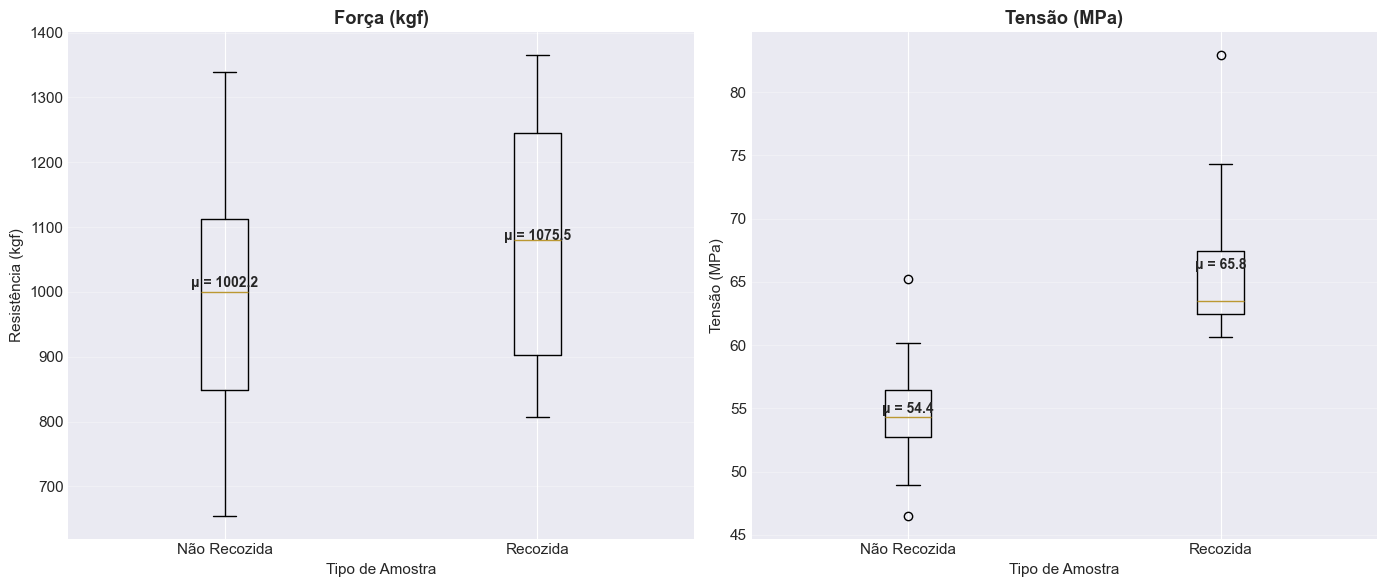

In [19]:
# Boxplot: comparação entre grupos, em FORÇA e em TENSÃO
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
rotulos = ['Não Recozida', 'Recozida']
for ax, col, ylab in [(axes[0], 'resistencia', 'Resistência (kgf)'), (axes[1], 'tensao_MPa', 'Tensão (MPa)')]:
    dados_plot = [df_validos.loc[df_validos['recozimento'] == g, col] for g in (0, 1)]
    # [CORREÇÃO] 'labels' foi renomeado para 'tick_labels' no matplotlib 3.9 e REMOVIDO na 3.11 (TypeError que você viu).
    # O try/except mantém compatibilidade com versões antigas, que só conhecem 'labels'.
    try:
        ax.boxplot(dados_plot, tick_labels=rotulos)
    except TypeError:
        ax.boxplot(dados_plot, labels=rotulos)
    for i, d in enumerate(dados_plot):
        ax.text(i + 1, d.mean(), f'μ = {d.mean():.1f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    ax.set_ylabel(ylab); ax.set_xlabel('Tipo de Amostra'); ax.grid(axis='y', alpha=0.3)
# [NOVO] Painel em tensão ao lado do de força: o ganho que não aparece em kgf fica visível em MPa.
axes[0].set_title('Força (kgf)', fontweight='bold'); axes[1].set_title('Tensão (MPa)', fontweight='bold')
plt.tight_layout(); plt.show()
# [CORREÇÃO] A célula de "diagnóstico" duplicada (que refazia a conversão com str.replace) foi removida: o gráfico agora usa
# df_validos, já numérico e sem falhas, em vez de reconverter df a cada célula.

# Matriz de Correlação

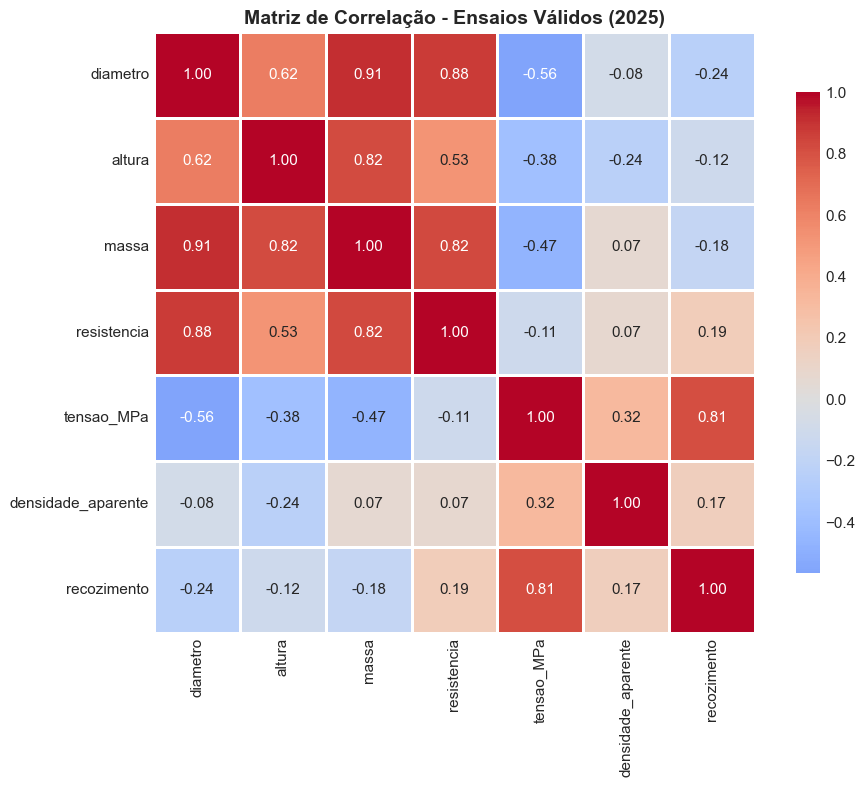


CORRELAÇÕES COM RESISTÊNCIA (força):
resistencia           1.000000
diametro              0.877038
massa                 0.823293
altura                0.527721
recozimento           0.186179
densidade_aparente    0.073919
tensao_MPa           -0.108746
Name: resistencia, dtype: float64

CORRELAÇÕES COM TENSÃO (MPa):
tensao_MPa            1.000000
recozimento           0.812148
densidade_aparente    0.324716
resistencia          -0.108746
altura               -0.381972
massa                -0.470119
diametro             -0.564668
Name: tensao_MPa, dtype: float64


In [ ]:
plt.figure(figsize=(10, 8))
#  'tensao_MPa' incluída na matriz: mostra que a correlação com o diâmetro, forte em força (0,88), inverte para negativa
# em tensão, ou seja, a força "enxerga" o tamanho da peça, e não a qualidade do material.
colunas_correlacao = ['diametro', 'altura', 'massa', 'resistencia', 'tensao_MPa', 'densidade_aparente', 'recozimento']

# Antes: df_validos['recozimento'].map({0: 0, 1: 1, '0': 0, '1': 1}) aplicado a texto ('SIM'/'NÃO') devolvia NaN,
# e a linha 'recozimento' saía vazia na matriz. Como agora a coluna já é 0/1, a correlação é calculada normalmente.
matriz_corr = df_validos[colunas_correlacao].corr()

sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Matriz de Correlação - Ensaios Válidos (2025)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print("\nCORRELAÇÕES COM RESISTÊNCIA (força):")
print(matriz_corr['resistencia'].sort_values(ascending=False))
print("\nCORRELAÇÕES COM TENSÃO (MPa):")
print(matriz_corr['tensao_MPa'].sort_values(ascending=False))
#  Interpretação: a correlação recozimento~resistência (agora calculável) é ≈0,19. O valor 0,07 citado no texto
# anterior era o da DENSIDADE APARENTE com a resistência (a linha 'recozimento' estava NaN, então foi lida a linha vizinha).

# Análise de Regressão Linear: Massa vs Resistência

In [ ]:
X_reg = df_validos[['massa']]
y_reg = df_validos['resistencia']

modelo_reg = LinearRegression().fit(X_reg, y_reg)
y_pred = modelo_reg.predict(X_reg)
df_validos['residuo'] = y_reg - y_pred
df_validos['predicao'] = y_pred
r2_forca = modelo_reg.score(X_reg, y_reg)

print("=" * 80)
print("MODELO DE REGRESSÃO LINEAR: MASSA vs RESISTÊNCIA")
print("=" * 80)
print(f"Coeficiente angular (slope): {modelo_reg.coef_[0]:.4f} kgf/g")
print(f"Intercepto: {modelo_reg.intercept_:.4f} kgf")
print(f"R² (coeficiente de determinação): {r2_forca:.4f}")
print(f"\nEquação: resistencia = {modelo_reg.coef_[0]:.4f} * massa + {modelo_reg.intercept_:.4f}")

#  Mesma regressão com a TENSÃO como resposta.
# Motivo técnico: se a massa explica ~68% da variância da FORÇA mas só ~22% da TENSÃO (com inclinação negativa), então a
# relação "mais massa → mais resistência" é efeito de tamanho (área), não de qualidade do material.
modelo_tensao = LinearRegression().fit(X_reg, df_validos['tensao_MPa'])
print(f"\n[Tensão] R² massa→tensão = {modelo_tensao.score(X_reg, df_validos['tensao_MPa']):.4f} | "
      f"slope = {modelo_tensao.coef_[0]:.3f} MPa/g")

#  Correlação tensão~diâmetro por grupo (efeito de escala / razão parede-preenchimento).
for g, nome in [(0, 'não recozidos'), (1, 'recozidos')]:
    s = df_validos[df_validos['recozimento'] == g]
    print(f"r(tensão, diâmetro) {nome}: {s['tensao_MPa'].corr(s['diametro']):.2f}")

MODELO DE REGRESSÃO LINEAR: MASSA vs RESISTÊNCIA
Coeficiente angular (slope): 93.3320 kgf/g
Intercepto: 572.3487 kgf
R² (coeficiente de determinação): 0.6778

Equação: resistencia = 93.3320 * massa + 572.3487

[Tensão] R² massa→tensão = 0.2210 | slope = -1.899 MPa/g
r(tensão, diâmetro) não recozidos: -0.64
r(tensão, diâmetro) recozidos: -0.73


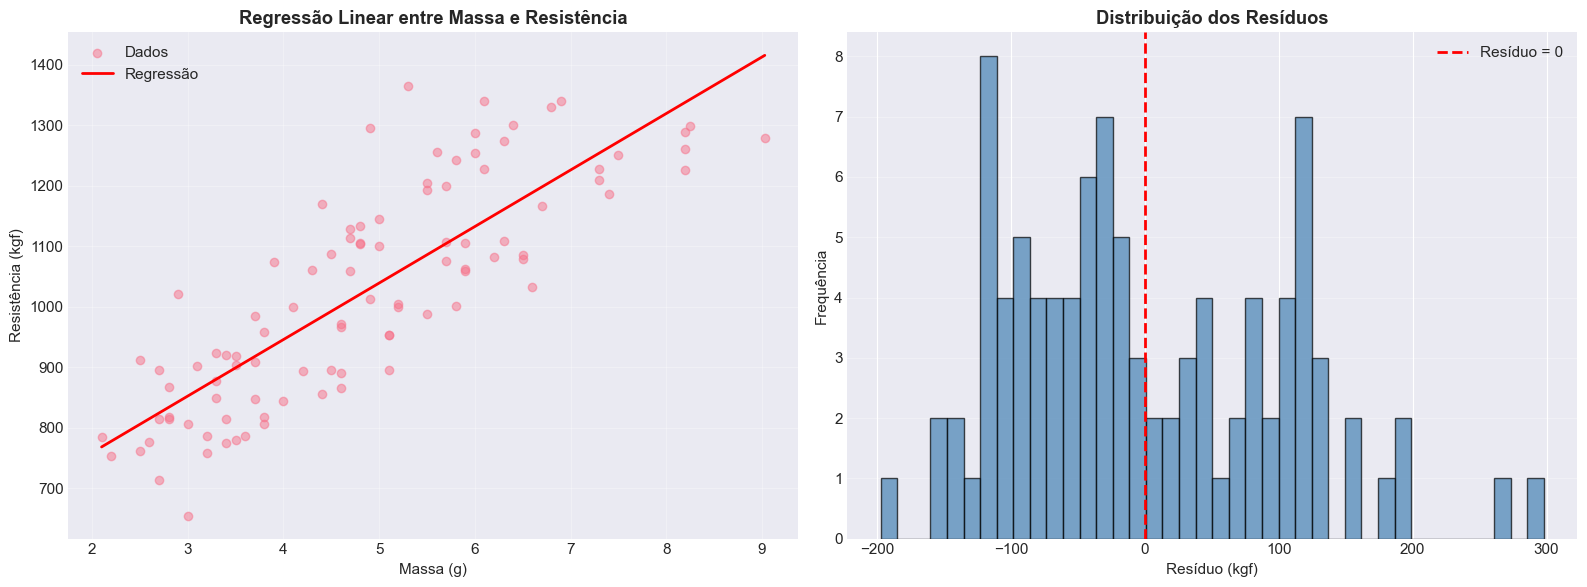

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(df_validos['massa'], df_validos['resistencia'], alpha=0.5, label='Dados')
#  Ordenação por massa antes de traçar a reta: plot() liga os pontos na ordem do DataFrame; com dados não ordenados
# o traço pode "zigue-zaguear" (aqui a reta é linear e sai igual, mas é a forma robusta).
ordem = np.argsort(df_validos['massa'].values)
axes[0].plot(df_validos['massa'].values[ordem], df_validos['predicao'].values[ordem], color='red', linewidth=2, label='Regressão')
axes[0].set_xlabel('Massa (g)'); axes[0].set_ylabel('Resistência (kgf)')
axes[0].set_title('Regressão Linear entre Massa e Resistência', fontweight='bold'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].hist(df_validos['residuo'], bins=40, edgecolor='black', alpha=0.7, color='steelblue')
axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label='Resíduo = 0')
axes[1].set_xlabel('Resíduo (kgf)'); axes[1].set_ylabel('Frequência')
axes[1].set_title('Distribuição dos Resíduos', fontweight='bold'); axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# Detecção de Anomalias com Isolation Forest (nos DOIS grupos, duas configurações)

**Mudança de abordagem:** o detector deixa de assumir que recozidas são livres de defeitos e passa a ser aplicado
**separadamente em cada grupo**. Duas configurações:
- **A (triagem pré-ensaio):** só variáveis não destrutivas: diâmetro, altura, massa, densidade aparente.
- **B (pós-ensaio, a original):** A + resistência (força).

In [23]:
#  A antiga versão remapeava 'recozimento' com um dicionário contendo chaves como 'NAO' e 'SIM ' e conversões em
# cadeia, que podiam produzir NaN silenciosos. Como 'recozimento' já é 0/1 desde o carregamento, o filtro é direto.
df_nao_recozidas = df_validos[df_validos['recozimento'] == 0].copy()
df_recozidas = df_validos[df_validos['recozimento'] == 1].copy()
print(f"Total de amostras NÃO recozidas: {len(df_nao_recozidas)}")
print(f"Total de amostras recozidas: {len(df_recozidas)}")

#  Verificação de sanidade das contagens esperadas (75 e 32 no total; 69 e 28 após remover falhas).
if (len(df_nao_recozidas), len(df_recozidas)) != (69, 28):
    warnings.warn("Contagens diferentes do esperado (69 não recozidas / 28 recozidas). Confira a base de dados.")

Total de amostras NÃO recozidas: 69
Total de amostras recozidas: 28


In [ ]:
# Variáveis de cada configuração.  A ORDEM das colunas é mantida igual à da versão anterior, porque o Isolation Forest
# sorteia atributos por índice de coluna: trocar a ordem muda quais árvores usam qual variável e pode alterar os sinalizados
# nos casos limítrofes (verificado: a config. B muda em 5% de contaminação se a ordem for alterada).
features_B = ['diametro', 'altura', 'massa', 'resistencia', 'densidade_aparente']   # original (inclui a força)
features_A = ['diametro', 'altura', 'massa', 'densidade_aparente']                  #  apenas não destrutivas

# [NOVO] Função única de detecção. Substitui as células de normalização/ajuste duplicadas (que usavam fillna(média) e dropna()).
def rodar_isolation_forest(df_grupo, features, contaminacao=CONTAMINACAO, semente=SEED):
    """Retorna Series (index = df_grupo.index) com -1 (anomalia) ou 1 (normal)."""
    X = df_grupo[features]
    #  Antes: X.fillna(X.mean()) e, em outra célula, X.dropna(). fillna(média) fabrica observações perfeitamente
    # "normais" (o IF as trata como típicas), e dropna() encurta X em relação ao DataFrame, desalinhando as predições com
    # os IDs. Aqui, dados faltantes interrompem a execução, e o resultado herda o índice do DataFrame (sem desalinhamento).
    if X.isna().any().any():
        raise ValueError("Há valores ausentes nas variáveis do Isolation Forest; trate-os explicitamente antes.")
    X_scaled = StandardScaler().fit_transform(X)   # IF é baseado em partições aleatórias, mas padronizar mantém a mesma
                                                   # convenção da versão anterior e evita que a escala dite o intervalo de corte
    modelo = IsolationForest(contamination=contaminacao, random_state=semente, n_estimators=N_ARVORES)
    return pd.Series(modelo.fit_predict(X_scaled), index=df_grupo.index)

#  'anomalia' é SEMPRE recalculada. Antes: "if 'anomalia' not in df.columns: ..." mantinha valores antigos ao
# reexecutar células fora de ordem (estado oculto do kernel), podendo plotar/exportar anomalias desatualizadas.
df_nao_recozidas['anomalia'] = rodar_isolation_forest(df_nao_recozidas, features_B)      # config. B = resultado original
df_nao_recozidas['anomalia_A'] = rodar_isolation_forest(df_nao_recozidas, features_A)    #  config. A
df_nao_recozidas['anomalia_B'] = df_nao_recozidas['anomalia']   # [AJUSTE] mesma coluna 'anomalia_B' nos dois grupos, para o código seguinte tratar NR e R igualmente

#  Detector também nas recozidas (antes presumidas livres de defeitos "por definição"). Motivo: premissa não verificável a
# priori; havia falhas de ensaio nas recozidas e o detector aponta peças atípicas nelas. Aqui só se mede, sem excluir.
df_recozidas['anomalia_B'] = rodar_isolation_forest(df_recozidas, features_B)
df_recozidas['anomalia_A'] = rodar_isolation_forest(df_recozidas, features_A)

ids = lambda d, col: sorted(d.loc[d[col] == -1, 'ID'].tolist())
print("NÃO RECOZIDAS  | Config. B (original):", ids(df_nao_recozidas, 'anomalia'))
print("NÃO RECOZIDAS  | Config. A (não destrutiva):", ids(df_nao_recozidas, 'anomalia_A'))
print("RECOZIDAS      | Config. B:", ids(df_recozidas, 'anomalia_B'), "| Config. A:", ids(df_recozidas, 'anomalia_A'))
print(f"\nOs {int(CONTAMINACAO*100)}% de contaminação definem QUANTOS pontos o IF sinaliza (~{CONTAMINACAO*len(df_nao_recozidas):.1f} de {len(df_nao_recozidas)}); "
      "o algoritmo escolhe QUAIS.")

NÃO RECOZIDAS  | Config. B (original): [270, 272, 277, 304, 340, 344]
NÃO RECOZIDAS  | Config. A (não destrutiva): [270, 277, 304, 340, 343, 344]
RECOZIDAS      | Config. B: [400, 408, 431] | Config. A: [400, 408, 431]

Os 8% de contaminação definem QUANTOS pontos o IF sinaliza (~5.5 de 69); o algoritmo escolhe QUAIS.


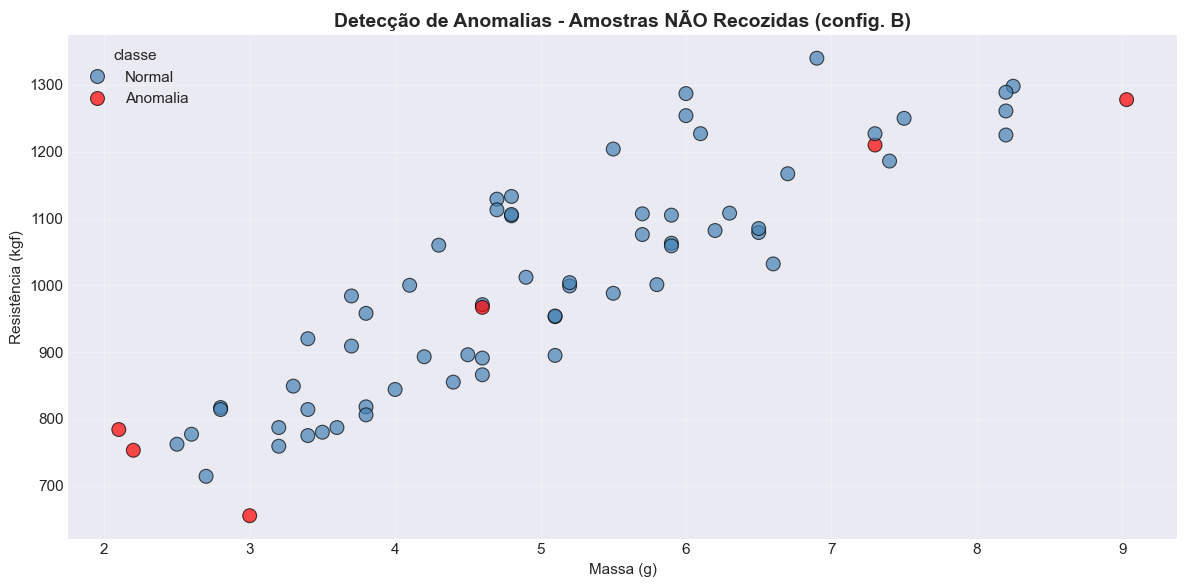

In [ ]:
# Plot: massa vs resistência
#  Tradução do rótulo feita nos DADOS (coluna de texto) em vez de plt.legend(labels=[...]) por cima do gráfico.
# O seaborn ordena a legenda conforme a primeira aparição dos valores; sobrescrever 'labels' na mão pode trocar
# "Normal"/"Anomalia" em relação às cores reais sem erro nenhum.
df_nao_recozidas['classe'] = df_nao_recozidas['anomalia'].map({1: 'Normal', -1: 'Anomalia'})

plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_nao_recozidas, x='massa', y='resistencia', hue='classe',
                palette={'Normal': 'steelblue', 'Anomalia': 'red'}, s=100, alpha=0.7, edgecolor='black')
plt.title('Detecção de Anomalias - Amostras NÃO Recozidas (config. B)', fontsize=14, fontweight='bold')
plt.xlabel('Massa (g)'); plt.ylabel('Resistência (kgf)'); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

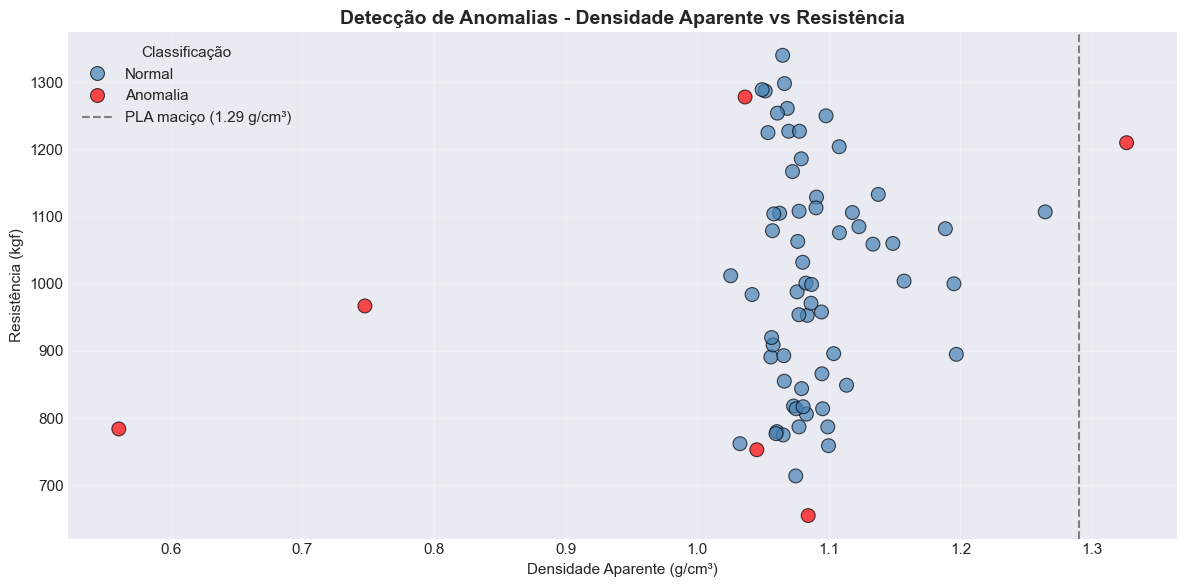

In [26]:
# Plot: densidade aparente vs resistência
# [CORREÇÃO] Eixo X em g/cm³ (densidade_gcm3): antes saía em g/mm³ (0,0006 a 0,0013), unidade que não é a usada nas referências.
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_nao_recozidas, x='densidade_gcm3', y='resistencia', hue='classe',
                palette={'Normal': 'steelblue', 'Anomalia': 'red'}, s=100, alpha=0.7, edgecolor='black')
#  Linha de referência do PLA maciço: pontos acima dela são fisicamente implausíveis para peça com 80% de preenchimento.
plt.axvline(RHO_PLA_INJETADO, color='gray', linestyle='--', label=f'PLA maciço ({RHO_PLA_INJETADO} g/cm³)')
plt.title('Detecção de Anomalias - Densidade Aparente vs Resistência', fontsize=14, fontweight='bold')
plt.xlabel('Densidade Aparente (g/cm³)'); plt.ylabel('Resistência (kgf)')
plt.legend(title='Classificação'); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

## Robustez da detecção (novos testes)

In [27]:
#  Sensibilidade ao parâmetro de contaminação (5%, 8%, 10%) nas não recozidas, configs. A e B.
# Motivo técnico: 'contamination' fixa o limiar de decisão (percentil do escore). O IF SEMPRE sinaliza essa fração, mesmo
# que não exista nenhuma anomalia real. Logo, "6 sinalizados" é consequência do parâmetro, e só é informativo saber QUAIS IDs
# permanecem quando o limiar muda.
sens = {}
for c in (0.05, 0.08, 0.10):
    sens[c] = {'A': set(ids_ for ids_ in df_nao_recozidas.loc[rodar_isolation_forest(df_nao_recozidas, features_A, c) == -1, 'ID']),
               'B': set(ids_ for ids_ in df_nao_recozidas.loc[rodar_isolation_forest(df_nao_recozidas, features_B, c) == -1, 'ID'])}
    print(f"contaminação {c:.2f} | A: {sorted(sens[c]['A'])} | B: {sorted(sens[c]['B'])}")
contagem = Counter(i for c in sens for cfg in sens[c] for i in sens[c][cfg])
print("\nIDs sinalizados em quantas das 6 combinações (3 contaminações × 2 configs):")
print(dict(sorted(contagem.items(), key=lambda kv: -kv[1])))

contaminação 0.05 | A: [270, 277, 304, 344] | B: [270, 277, 340, 344]
contaminação 0.08 | A: [270, 277, 304, 340, 343, 344] | B: [270, 272, 277, 304, 340, 344]
contaminação 0.10 | A: [270, 273, 277, 304, 340, 343, 344] | B: [270, 272, 277, 304, 340, 342, 344]

IDs sinalizados em quantas das 6 combinações (3 contaminações × 2 configs):
{344: 6, 277: 6, 270: 6, 304: 5, 340: 5, 343: 2, 272: 2, 273: 1, 342: 1}


In [28]:
# Estabilidade em 200 sementes aleatórias, por grupo e por configuração.
# Motivo técnico: o IF usa subamostragem e cortes aleatórios; com uma única semente (42) um ID pode ser sinalizado "por acaso".
# A frequência com que cada ID é sinalizado separa achados estáveis (~100%) de limítrofes (~30–70%).
def estabilidade(df_grupo, features, n=N_SEMENTES_ESTAB):
    cont = Counter()
    for s in range(n):
        pred = rodar_isolation_forest(df_grupo, features, CONTAMINACAO, s)
        cont.update(df_grupo.loc[pred == -1, 'ID'].tolist())
    return {k: 100 * v / n for k, v in cont.items()}

estab = {
    ('NR', 'A'): estabilidade(df_nao_recozidas, features_A),
    ('NR', 'B'): estabilidade(df_nao_recozidas, features_B),
    ('R', 'A'): estabilidade(df_recozidas, features_A),
    ('R', 'B'): estabilidade(df_recozidas, features_B),
}
for (g, cfg), d in estab.items():
    top = {k: round(v, 1) for k, v in sorted(d.items(), key=lambda kv: -kv[1]) if v >= 20}
    print(f"{g} config {cfg}: IDs sinalizados em ≥20% das {N_SEMENTES_ESTAB} sementes -> {top}")

NR config A: IDs sinalizados em ≥20% das 200 sementes -> {344: 100.0, 270: 100.0, 340: 100.0, 304: 100.0, 277: 100.0, 343: 75.5}
NR config B: IDs sinalizados em ≥20% das 200 sementes -> {344: 100.0, 340: 100.0, 277: 100.0, 304: 99.0, 270: 93.5, 342: 61.5, 272: 43.0}
R config A: IDs sinalizados em ≥20% das 200 sementes -> {400: 96.5, 408: 89.5, 431: 80.5, 411: 31.0}
R config B: IDs sinalizados em ≥20% das 200 sementes -> {408: 100.0, 431: 68.0, 400: 65.5, 411: 60.5}


## Confiança dos sinalizados: bootstrap (substitui o gabarito)

**Por que:** sem gabarito não é possível calcular a taxa de falsos positivos diretamente. O bootstrap mede o quão **robusta** é cada sinalização: o modelo é retreinado 200 vezes em reamostras com reposição da própria base. Amostra realmente atípica tende a ser sinalizada na maioria das rodadas; amostra sinalizada "por acaso" alterna entre normal e anômala.

**O que isto NÃO prova:** estabilidade não é prova de defeito. Um erro sistemático de medição (por exemplo, massa registrada errada) é perfeitamente estável. Por isso a classificação abaixo é de **confiança da sinalização**, e a confirmação do defeito exige tomografia ou microscopia.

In [30]:
#  Bootstrap de estabilidade (mesma lógica do projeto CBECIMAT: reamostra com reposição, treina, aplica na base ORIGINAL).
# Diferença para a "estabilidade em 200 sementes" acima: as sementes variam apenas o sorteio interno do algoritmo sobre os MESMOS dados;
# o bootstrap varia os DADOS (o que equivale a perguntar "e se a amostra tivesse sido outra?"), que é a incerteza relevante aqui.
N_BOOT = 200
LIM_ROBUSTA, LIM_FRONTEIRA = 90, 50    # mesmos limiares do CBECIMAT, para comparabilidade entre os dois estudos

def bootstrap_estabilidade(df_grupo, features, contaminacao=CONTAMINACAO, n_iter=N_BOOT, base=SEED):
    X0 = df_grupo[features].values
    n = len(df_grupo)
    contagem = np.zeros(n)
    for i in range(n_iter):
        idx = np.random.RandomState(base + i).choice(n, size=n, replace=True)   # reamostragem com reposição
        # Normalização ajustada SÓ na reamostra: evita vazamento de informação da base original para o ajuste do modelo.
        scaler = StandardScaler().fit(X0[idx])
        modelo = IsolationForest(contamination=contaminacao, random_state=base + i, n_estimators=N_ARVORES)
        modelo.fit(scaler.transform(X0[idx]))
        # Aplica na base ORIGINAL completa: assim TODA amostra é avaliada em TODAS as rodadas (inclusive as não sorteadas no treino).
        contagem += (modelo.predict(scaler.transform(X0)) == -1)
    return pd.Series(100 * contagem / n_iter, index=df_grupo['ID'].values)

def classificar_confianca(p):
    # >= 90%: alta confiança | 50-90%: fronteira (cautela) | < 50%: provável falso positivo
    return 'robusta' if p >= LIM_ROBUSTA else ('fronteira' if p >= LIM_FRONTEIRA else 'falso positivo provável')

boot = {('NR', 'A'): bootstrap_estabilidade(df_nao_recozidas, features_A), ('NR', 'B'): bootstrap_estabilidade(df_nao_recozidas, features_B),
        ('R', 'A'): bootstrap_estabilidade(df_recozidas, features_A), ('R', 'B'): bootstrap_estabilidade(df_recozidas, features_B)}

# Guarda o resultado nas tabelas de cada grupo e classifica SOMENTE quem foi sinalizado na execução-base.
for df_g, g in [(df_nao_recozidas, 'NR'), (df_recozidas, 'R')]:
    for cfg in ('A', 'B'):
        df_g[f'boot_{cfg}_pct'] = df_g['ID'].map(boot[(g, cfg)]).round(1)
        sinal = df_g[f'anomalia_{cfg}'] == -1
        df_g[f'classe_{cfg}'] = np.where(sinal, df_g[f'boot_{cfg}_pct'].apply(classificar_confianca), 'normal')

# Terminologia: "sinalizada" = saída bruta do IF; "amostra anômala" = sinalizada COM a confiança medida pelo bootstrap.
for g, df_g in [('NÃO RECOZIDAS', df_nao_recozidas), ('RECOZIDAS', df_recozidas)]:
    print("=" * 80); print(f"AMOSTRAS ANÔMALAS - {g}"); print("=" * 80)
    for cfg in ('A', 'B'):
        tab_cfg = df_g[df_g[f'anomalia_{cfg}'] == -1][['ID', f'boot_{cfg}_pct', f'classe_{cfg}']].sort_values(f'boot_{cfg}_pct', ascending=False)
        print(f"\nConfig. {cfg}:"); display(tab_cfg.reset_index(drop=True))   #  não usar 't' como variável: sobrescreveria scipy.stats.t

AMOSTRAS ANÔMALAS - NÃO RECOZIDAS

Config. A:


,ID,boot_A_pct,classe_A
0,277,96.5,robusta
1,344,96.0,robusta
2,340,89.0,fronteira
3,270,80.5,fronteira
4,304,68.0,fronteira
5,343,52.0,fronteira



Config. B:


,ID,boot_B_pct,classe_B
0,344,94.0,robusta
1,277,93.5,robusta
2,340,84.0,fronteira
3,270,72.5,fronteira
4,304,60.0,fronteira
5,272,38.5,falso positivo provável


AMOSTRAS ANÔMALAS - RECOZIDAS

Config. A:


,ID,boot_A_pct,classe_A
0,408,66.5,fronteira
1,400,63.5,fronteira
2,431,55.5,fronteira



Config. B:


,ID,boot_B_pct,classe_B
0,408,67.5,fronteira
1,431,58.5,fronteira
2,400,52.0,fronteira


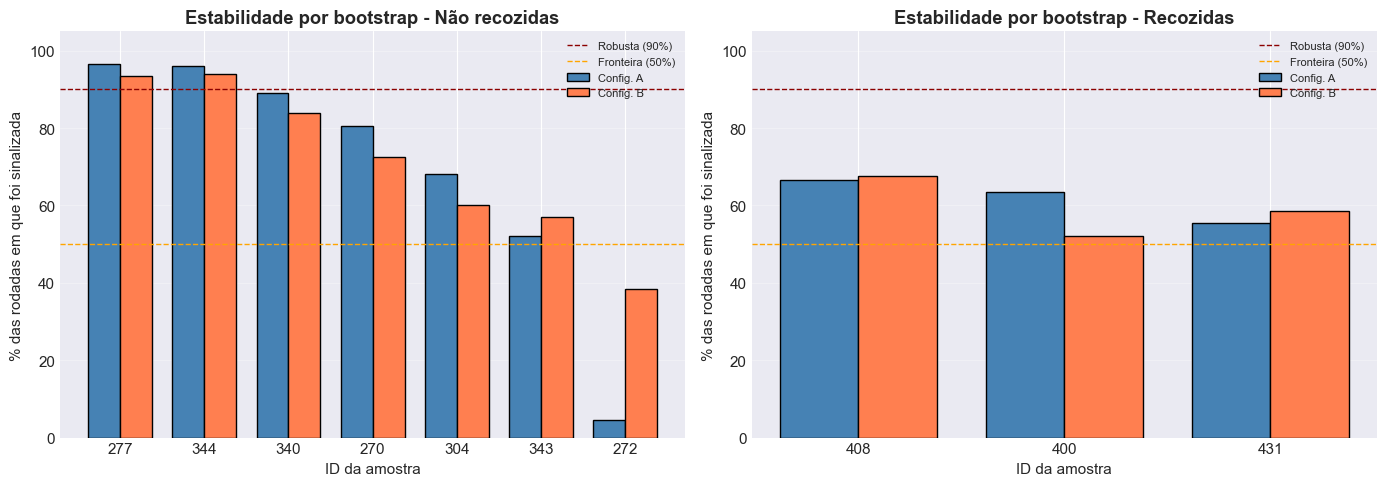

In [31]:
# Gráfico de estabilidade por bootstrap (equivalente ao do CBECIMAT), um painel por grupo e barras para as configs. A e B.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (df_g, titulo) in zip(axes, [(df_nao_recozidas, 'Não recozidas'), (df_recozidas, 'Recozidas')]):
    sel = df_g[(df_g['anomalia_A'] == -1) | (df_g['anomalia_B'] == -1)].sort_values('boot_A_pct', ascending=False)
    x = np.arange(len(sel)); w = 0.38
    ax.bar(x - w/2, sel['boot_A_pct'], w, label='Config. A', color='steelblue', edgecolor='black')
    ax.bar(x + w/2, sel['boot_B_pct'], w, label='Config. B', color='coral', edgecolor='black')
    ax.axhline(LIM_ROBUSTA, color='darkred', ls='--', lw=1, label=f'Robusta ({LIM_ROBUSTA}%)')
    ax.axhline(LIM_FRONTEIRA, color='orange', ls='--', lw=1, label=f'Fronteira ({LIM_FRONTEIRA}%)')
    ax.set_xticks(x); ax.set_xticklabels(sel['ID'].astype(int).astype(str)); ax.set_ylim(0, 105)
    ax.set_xlabel('ID da amostra'); ax.set_ylabel('% das rodadas em que foi sinalizada'); ax.set_title(f'Estabilidade por bootstrap - {titulo}', fontweight='bold')
    ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

In [32]:
# Tabela de interpretação dos sinalizados (não recozidos): variáveis físicas + estabilidade.
# Motivo: o IF diz que o ponto é ATÍPICO, não que é DEFEITUOSO. Densidade muito baixa sugere vazios; densidade acima do PLA
# maciço sugere erro de medição; ponto extremo em diâmetro/massa é só alavancagem geométrica.
flag_ids = sorted(set(ids(df_nao_recozidas, 'anomalia')) | set(ids(df_nao_recozidas, 'anomalia_A')))
tabela = df_nao_recozidas[df_nao_recozidas['ID'].isin(flag_ids)][
    ['ID', 'diametro', 'altura', 'massa', 'densidade_gcm3', 'resistencia', 'tensao_MPa', 'anomalia_A', 'anomalia']].copy()
tabela['sinal_A'] = (tabela['anomalia_A'] == -1); tabela['sinal_B'] = (tabela['anomalia'] == -1)
tabela['estab_A_%'] = tabela['ID'].map(lambda i: estab[('NR', 'A')].get(i, 0)).round(1)
tabela['estab_B_%'] = tabela['ID'].map(lambda i: estab[('NR', 'B')].get(i, 0)).round(1)
#  Confiança por bootstrap ao lado das variáveis físicas: separa "atípica e robusta" de "atípica mas instável".
tabela['boot_A_%'] = tabela['ID'].map(boot[('NR', 'A')]).round(1)
tabela['boot_B_%'] = tabela['ID'].map(boot[('NR', 'B')]).round(1)
display(tabela.drop(columns=['anomalia_A', 'anomalia']).round(2).sort_values('ID').reset_index(drop=True))

#  Sinalizados são mais fracos que os demais? (Mann-Whitney: n = 6 é pequeno demais para assumir normalidade)
# Motivo: a antiga conclusão "outliers têm média menor, logo a detecção funciona" não tinha teste. Com n = 6 e dispersão
# grande, a diferença de médias pode ser só ruído amostral.
for col_pred, cfg in [('anomalia', 'B'), ('anomalia_A', 'A')]:
    s = df_nao_recozidas[df_nao_recozidas[col_pred] == -1]; o = df_nao_recozidas[df_nao_recozidas[col_pred] == 1]
    print(f"\nConfig. {cfg}: sinalizados (n={len(s)}) vs demais (n={len(o)})")
    for var in ['resistencia', 'tensao_MPa', 'densidade_gcm3']:
        print(f"   {var:15s} média {s[var].mean():9.2f} vs {o[var].mean():9.2f} | Mann-Whitney p = {stats.mannwhitneyu(s[var], o[var]).pvalue:.3f}")

,ID,diametro,altura,massa,densidade_gcm3,resistencia,tensao_MPa,sinal_A,sinal_B,estab_A_%,estab_B_%,boot_A_%,boot_B_%
0,270,12.50,17.15,2.20,1.05,753.0,60.17,True,True,100.0,93.5,80.5,72.5
1,272,12.33,23.17,3.00,1.08,655.0,53.80,False,True,0.0,43.0,4.5,38.5
2,277,13.09,27.84,2.10,0.56,784.0,57.13,True,True,100.0,100.0,96.5,93.5
3,304,16.11,30.19,4.60,0.75,967.0,46.52,True,True,100.0,99.0,68.0,60.0
4,340,17.38,23.20,7.30,1.33,1210.0,50.02,True,True,100.0,100.0,89.0,84.0
5,343,18.10,30.37,8.20,1.05,1289.0,49.13,True,False,75.5,2.0,52.0,57.0
6,344,18.05,34.05,9.03,1.04,1278.0,48.98,True,True,100.0,100.0,96.0,94.0



Config. B: sinalizados (n=6) vs demais (n=63)
   resistencia     média    941.17 vs   1008.06 | Mann-Whitney p = 0.354
   tensao_MPa      média     52.77 vs     54.51 | Mann-Whitney p = 0.398
   densidade_gcm3  média      0.97 vs      1.09 | Mann-Whitney p = 0.083

Config. A: sinalizados (n=6) vs demais (n=63)
   resistencia     média   1046.83 vs    998.00 | Mann-Whitney p = 0.647
   tensao_MPa      média     51.99 vs     54.58 | Mann-Whitney p = 0.154
   densidade_gcm3  média      0.96 vs      1.09 | Mann-Whitney p = 0.010


In [33]:
# Teste da premissa "recozidas não têm anomalias": o que o mesmo detector aponta no grupo recozido?
# Motivo: se o detector (que só conhece a distribuição do próprio grupo) sinaliza peças recozidas e há falhas de ensaio nelas
# (4/32), a premissa não se sustenta como hipótese de partida.
tab_r = df_recozidas[(df_recozidas['anomalia_A'] == -1) | (df_recozidas['anomalia_B'] == -1)][
    ['ID', 'diametro', 'massa', 'densidade_gcm3', 'resistencia', 'tensao_MPa', 'anomalia_A', 'anomalia_B']]
tab_r = tab_r.assign(estab_A=lambda d: d['ID'].map(lambda i: round(estab[('R', 'A')].get(i, 0), 1)),
                     estab_B=lambda d: d['ID'].map(lambda i: round(estab[('R', 'B')].get(i, 0), 1)),
                     boot_A=lambda d: d['ID'].map(boot[('R', 'A')]).round(1), boot_B=lambda d: d['ID'].map(boot[('R', 'B')]).round(1))
#  Com n = 28 o bootstrap é mais ruidoso (reamostras com muitos duplicados). Interpretar 'fronteira' nas recozidas com mais cautela.
display(tab_r.round(2).reset_index(drop=True))

,ID,diametro,massa,densidade_gcm3,resistencia,tensao_MPa,anomalia_A,anomalia_B,estab_A,estab_B,boot_A,boot_B
0,400,12.4,2.5,1.16,912.0,74.06,-1,-1,96.5,65.5,63.5,52.0
1,408,12.4,2.9,1.25,1021.0,82.91,-1,-1,89.5,100.0,66.5,67.5
2,431,16.3,6.8,1.08,1329.0,62.46,-1,-1,80.5,68.0,55.5,58.5


# Criação dos Grupos Finais para Comparação

In [34]:
# Grupos originais mantidos (config. B), para compatibilidade com os CSVs e figuras anteriores.
# [CORREÇÃO] Atribuições feitas sobre cópias explícitas (.copy() acima); evita SettingWithCopyWarning e a chance de escrever
# numa "view" do DataFrame original.
df_recozidas['grupo_final'] = 'recozido'
df_recozidas['anomalia'] = 1   # compatibilidade: mantém a coluna usada nas versões anteriores (recozidas fora da lista de suspeitos)
df_nao_recozidas['grupo_final'] = df_nao_recozidas['anomalia'].map({1: 'nao_outlier', -1: 'outlier'})

df_final = pd.concat([df_nao_recozidas, df_recozidas], ignore_index=True)

print("=" * 80); print("DISTRIBUIÇÃO FINAL DOS GRUPOS"); print("=" * 80)
print(df_final['grupo_final'].value_counts()); print(f"\nTotal de amostras: {len(df_final)}")

DISTRIBUIÇÃO FINAL DOS GRUPOS
grupo_final
nao_outlier    63
recozido       28
outlier         6
Name: count, dtype: int64

Total de amostras: 97


In [35]:
print("=" * 80); print("ESTATÍSTICAS POR GRUPO FINAL"); print("=" * 80)
for grupo in ['outlier', 'nao_outlier', 'recozido']:
    print(f"\n{'=' * 40}\nGRUPO: {grupo.upper()}\n{'=' * 40}")
    display(df_final[df_final['grupo_final'] == grupo][['massa', 'resistencia', 'tensao_MPa', 'densidade_gcm3']].describe())

ESTATÍSTICAS POR GRUPO FINAL

GRUPO: OUTLIER


,massa,resistencia,tensao_MPa,densidade_gcm3
count,6.00000,6.000000,6.000000,6.000000
mean,4.70500,941.166667,52.769653,0.966735
std,2.87815,256.279080,5.212649,0.271015
min,2.10000,655.000000,46.522837,0.560507
25%,2.40000,760.750000,49.238244,0.819728
50%,3.80000,875.500000,51.906191,1.040858
75%,6.62500,1149.250000,56.296704,1.074610
max,9.03000,1278.000000,60.173565,1.326311



GRUPO: NAO_OUTLIER


,massa,resistencia,tensao_MPa,densidade_gcm3
count,63.000000,63.000000,63.000000,63.000000
mean,5.042063,1008.063492,54.507898,1.089037
std,1.520351,166.721893,2.742374,0.041688
min,2.500000,714.000000,49.127715,1.025467
25%,3.800000,860.500000,52.873671,1.065132
50%,4.800000,1001.000000,54.603210,1.077721
75%,6.000000,1110.500000,56.409813,1.098576
max,8.250000,1340.000000,65.201143,1.264466



GRUPO: RECOZIDO


,massa,resistencia,tensao_MPa,densidade_gcm3
count,28.000000,28.000000,28.000000,28.000000
mean,4.389286,1075.535714,65.750869,1.110050
std,1.320308,182.894724,5.149110,0.057930
min,2.500000,807.000000,60.612998,1.055322
25%,3.250000,902.750000,62.466068,1.079581
50%,4.450000,1080.000000,63.494711,1.088754
75%,5.525000,1245.500000,67.440718,1.109039
max,6.800000,1365.000000,82.911193,1.250079


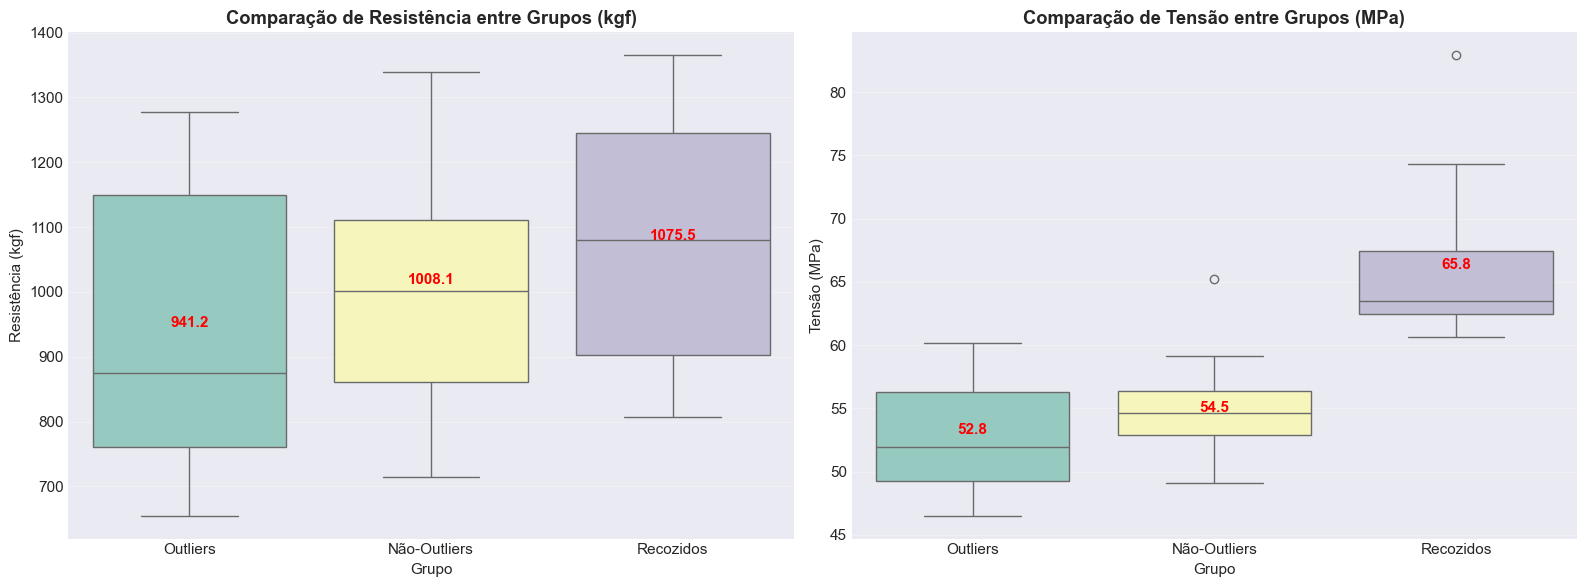

In [36]:
# Boxplot comparando os 3 grupos (força e tensão)
ordem_grupos = ['outlier', 'nao_outlier', 'recozido']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, ylab in [(axes[0], 'resistencia', 'Resistência (kgf)'), (axes[1], 'tensao_MPa', 'Tensão (MPa)')]:
    #  seaborn ≥0.13: usar 'palette' sem 'hue' é descontinuado (FutureWarning). Atribuir hue=x e legend=False é equivalente.
    sns.boxplot(data=df_final, x='grupo_final', y=col, order=ordem_grupos, hue='grupo_final', hue_order=ordem_grupos,
                palette='Set3', legend=False, ax=ax)
    ax.set_xlabel('Grupo'); ax.set_ylabel(ylab); ax.grid(axis='y', alpha=0.3)
    # set_xticks antes de set_xticklabels: rotular sem fixar as posições gera UserWarning e pode desalinhar rótulos.
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(['Outliers', 'Não-Outliers', 'Recozidos'])
    for i, g in enumerate(ordem_grupos):
        m = df_final.loc[df_final['grupo_final'] == g, col].mean()
        ax.text(i, m, f'{m:.1f}', ha='center', va='bottom', fontweight='bold', color='red')
axes[0].set_title('Comparação de Resistência entre Grupos (kgf)', fontweight='bold')
axes[1].set_title('Comparação de Tensão entre Grupos (MPa)', fontweight='bold')   # [NOVO]
plt.tight_layout(); plt.show()

# Comparação Estatística: efeito do recozimento

Comparações feitas com a mesma função, em **força** e em **tensão**, e em vários recortes.

In [ ]:
#  Função única de comparação entre dois grupos.
# Reúne, na mesma saída, tudo o que é necessário para interpretar o resultado:
#  - Shapiro-Wilk (decide se o teste paramétrico é adequado);
#  - t de Student (variâncias iguais, como na versão anterior) E t de Welch. Welch é o padrão recomendado porque não exige
#    variâncias iguais, e aqui elas diferem (DP 3,0 vs 5,2 MPa); com n diferentes, o Student fica inflado ou conservador;
#  - Mann-Whitney (não paramétrico);
#  - diferença de médias com IC 95% (informa magnitude, não só "significativo ou não");
#  - g de Hedges (tamanho de efeito paramétrico, com correção de viés para amostras pequenas);
#  - δ de Cliff (tamanho de efeito não paramétrico, em [-1, 1], robusto a assimetria).
def comparar_grupos(x, y, nome, unidade):
    x = np.asarray(x, float); y = np.asarray(y, float)
    nx, ny = len(x), len(y)
    sw_x, sw_y = stats.shapiro(x), stats.shapiro(y)
    st = stats.ttest_ind(x, y)                      # Student
    we = stats.ttest_ind(x, y, equal_var=False)     # Welch
    mw = stats.mannwhitneyu(x, y, alternative='two-sided')
    dif = y.mean() - x.mean()
    se = np.sqrt(x.var(ddof=1) / nx + y.var(ddof=1) / ny)
    gl = se**4 / ((x.var(ddof=1) / nx)**2 / (nx - 1) + (y.var(ddof=1) / ny)**2 / (ny - 1))   # Welch–Satterthwaite
    ic = (dif - t.ppf(0.975, gl) * se, dif + t.ppf(0.975, gl) * se)
    sp = np.sqrt(((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / (nx + ny - 2))
    g = dif / sp * (1 - 3 / (4 * (nx + ny) - 9))
    delta = 1 - 2 * mw.statistic / (nx * ny)        # δ de Cliff para "y > x"
    print("=" * 80); print(f"{nome}  [{unidade}]   n = {nx} vs {ny}"); print("=" * 80)
    print(f"Média ± DP: {x.mean():.2f} ± {x.std(ddof=1):.2f}  vs  {y.mean():.2f} ± {y.std(ddof=1):.2f}")
    print(f"Shapiro-Wilk: p = {sw_x.pvalue:.4f} (grupo 1) | p = {sw_y.pvalue:.4f} (grupo 2)")
    print(f"t de Student : t = {st.statistic:.3f}, p = {st.pvalue:.4g}")
    print(f"t de Welch   : t = {we.statistic:.3f}, gl = {gl:.1f}, p = {we.pvalue:.4g}")
    print(f"Mann-Whitney : U = {mw.statistic:.0f}, p = {mw.pvalue:.4g}")
    print(f"Diferença    : {dif:+.2f} {unidade} (IC 95%: {ic[0]:.2f} a {ic[1]:.2f}) = {100 * dif / x.mean():+.2f}%")
    print(f"Tamanho de efeito: g de Hedges = {g:.2f} | δ de Cliff = {delta:.2f}")
    sig = we.pvalue < ALFA and mw.pvalue < ALFA
    #  A conclusão agora é DERIVADA dos p-valores. Antes o texto do artigo afirmava "p < 0,05" sem que o código
    # o verificasse, e na versão em força os p calculados eram 0,087 / 0,094 / 0,102 (não significativos).
    print(f"Conclusão (α = {ALFA}): {'diferença significativa nos dois testes' if sig else 'SEM evidência suficiente de diferença (pelo menos um teste não significativo)'}\n")
    return dict(nome=nome, dif=dif, pct=100 * dif / x.mean(), p_welch=we.pvalue, p_mw=mw.pvalue, g=g, delta=delta, ic=ic)

res = {}
nao_out = df_final[df_final['grupo_final'] == 'nao_outlier']
rec = df_final[df_final['grupo_final'] == 'recozido']
nr_todas = df_final[df_final['recozimento'] == 0]

In [38]:
# 1) Comparação ORIGINAL (força, não-outliers config. B vs recozidos). Mantida para rastrear o resultado anterior.
res['forca_original'] = comparar_grupos(nao_out['resistencia'], rec['resistencia'], 'FORÇA: não-outliers (B) vs recozidos', 'kgf')

# 2)  Força com TODOS os ensaios válidos (sem excluir sinalizados). Motivo: excluir só do grupo não recozido é uma
# assimetria (os recozidos também têm pontos atípicos); usar todos os válidos é o teste sem seleção prévia.
res['forca_todas'] = comparar_grupos(nr_todas['forca_kN'], rec['forca_kN'], 'FORÇA: todas as não recozidas vs recozidas', 'kN')

FORÇA: não-outliers (B) vs recozidos  [kgf]   n = 63 vs 28
Média ± DP: 1008.06 ± 166.72  vs  1075.54 ± 182.89
Shapiro-Wilk: p = 0.0507 (grupo 1) | p = 0.0299 (grupo 2)
t de Student : t = -1.729, p = 0.08723
t de Welch   : t = -1.668, gl = 47.8, p = 0.1018
Mann-Whitney : U = 687, p = 0.09442
Diferença    : +67.47 kgf (IC 95%: -13.86 a 148.80) = +6.69%
Tamanho de efeito: g de Hedges = 0.39 | δ de Cliff = 0.22
Conclusão (α = 0.05): SEM evidência suficiente de diferença (pelo menos um teste não significativo)

FORÇA: todas as não recozidas vs recozidas  [kN]   n = 69 vs 28
Média ± DP: 9.83 ± 1.71  vs  10.55 ± 1.79
Shapiro-Wilk: p = 0.0516 (grupo 1) | p = 0.0299 (grupo 2)
t de Student : t = -1.847, p = 0.06787
t de Welch   : t = -1.811, gl = 48.1, p = 0.07634
Mann-Whitney : U = 741, p = 0.07389
Diferença    : +0.72 kN (IC 95%: -0.08 a 1.52) = +7.31%
Tamanho de efeito: g de Hedges = 0.41 | δ de Cliff = 0.23
Conclusão (α = 0.05): SEM evidência suficiente de diferença (pelo menos um teste não 

In [39]:
# 3)  TENSÃO (MPa), todos os ensaios válidos. É a comparação fisicamente adequada: a tensão normaliza pela área da seção.
res['tensao_todas'] = comparar_grupos(nr_todas['tensao_MPa'], rec['tensao_MPa'], 'TENSÃO: todas as não recozidas vs recozidas', 'MPa')

# 4)  TENSÃO sem os sinalizados (config. A) nos DOIS grupos: teste de sensibilidade. Motivo: mostrar que o resultado
# não depende de manter/excluir os pontos atípicos (e que a exclusão é simétrica entre os grupos).
nr_sem = df_final[(df_final['recozimento'] == 0) & (df_final['anomalia_A'] == 1)]
rec_sem = df_final[(df_final['recozimento'] == 1) & (df_final['anomalia_A'] == 1)]   # anomalia_A das recozidas é do detector, não 'por definição'
res['tensao_sem_sinal'] = comparar_grupos(nr_sem['tensao_MPa'], rec_sem['tensao_MPa'],
                                          'TENSÃO: sem sinalizados (config. A) nos dois grupos', 'MPa')

TENSÃO: todas as não recozidas vs recozidas  [MPa]   n = 69 vs 28
Média ± DP: 54.36 ± 3.02  vs  65.75 ± 5.15
Shapiro-Wilk: p = 0.1230 (grupo 1) | p = 0.0001 (grupo 2)
t de Student : t = -13.567, p = 5.894e-24
t de Welch   : t = -10.970, gl = 34.8, p = 7.733e-13
Mann-Whitney : U = 17, p = 4.315e-14
Diferença    : +11.39 MPa (IC 95%: 9.29 a 13.50) = +20.96%
Tamanho de efeito: g de Hedges = 3.02 | δ de Cliff = 0.98
Conclusão (α = 0.05): diferença significativa nos dois testes

TENSÃO: sem sinalizados (config. A) nos dois grupos  [MPa]   n = 63 vs 25
Média ± DP: 54.58 ± 2.66  vs  64.86 ± 3.66
Shapiro-Wilk: p = 0.0090 (grupo 1) | p = 0.0011 (grupo 2)
t de Student : t = -14.639, p = 4.503e-25
t de Welch   : t = -12.769, gl = 34.5, p = 1.255e-14
Mann-Whitney : U = 16, p = 9.777e-13
Diferença    : +10.28 MPa (IC 95%: 8.65 a 11.92) = +18.84%
Tamanho de efeito: g de Hedges = 3.43 | δ de Cliff = 0.98
Conclusão (α = 0.05): diferença significativa nos dois testes



In [40]:
#  Intervalos de confiança de 95% das MÉDIAS (função da versão anterior), agora também em tensão.
def intervalo_confianca_95(dados):
    n = len(dados); media = dados.mean(); erro = sem(dados) * t.ppf((1 + 0.95) / 2, n - 1)
    return media - erro, media + erro
print("=" * 80); print("INTERVALOS DE CONFIANÇA (95%) DAS MÉDIAS"); print("=" * 80)
for nome, serie in [('Força não recozidas (kgf)', nr_todas['resistencia']), ('Força recozidas (kgf)', rec['resistencia']),
                    ('Tensão não recozidas (MPa)', nr_todas['tensao_MPa']), ('Tensão recozidas (MPa)', rec['tensao_MPa'])]:
    lo, hi = intervalo_confianca_95(serie); print(f"{nome:30s}: [{lo:.2f}, {hi:.2f}]")

INTERVALOS DE CONFIANÇA (95%) DAS MÉDIAS
Força não recozidas (kgf)     : [960.27, 1044.22]
Força recozidas (kgf)         : [1004.62, 1146.45]
Tensão não recozidas (MPa)    : [53.63, 55.08]
Tensão recozidas (MPa)        : [63.75, 67.75]


## Controle do tamanho da peça (novos testes)

In [41]:
#  Regressão da TENSÃO sobre recozimento + diâmetro, com erros robustos HC3.
# Motivo técnico: os grupos têm diâmetros diferentes, e a tensão varia com o diâmetro (efeito de escala/razão parede-preenchimento).
# O coeficiente de 'recozimento' é o efeito do tratamento A DIÂMETRO IGUAL. HC3 é robusto à heterocedasticidade (o DP é maior nos
# recozidos) e aceitável para amostras pequenas; o OLS comum teria erros-padrão enviesados.
def ols_robusto(y, colunas, dados, rotulo):
    X = sm.add_constant(dados[colunas]); m = sm.OLS(dados[y], X).fit(cov_type='HC3')
    ic = m.conf_int().loc['recozimento']
    print(f"{rotulo}: efeito do recozimento = {m.params['recozimento']:+.2f} (IC 95%: {ic[0]:.2f} a {ic[1]:.2f}), p = {m.pvalues['recozimento']:.3g}, R² = {m.rsquared:.3f}")
    if 'diametro' in colunas: print(f"        coeficiente do diâmetro = {m.params['diametro']:+.2f} por mm")
    return m
print("=" * 80); print("REGRESSÃO (OLS, erros HC3)"); print("=" * 80)
m_t0 = ols_robusto('tensao_MPa', ['recozimento'], df_validos, 'Tensão ~ recozimento (MPa)')
m_t1 = ols_robusto('tensao_MPa', ['recozimento', 'diametro'], df_validos, 'Tensão ~ recozimento + diâmetro (MPa)')
m_f1 = ols_robusto('resistencia', ['recozimento', 'diametro'], df_validos, 'Força ~ recozimento + diâmetro (kgf)')
# Leitura: a força "bruta" não diferia entre grupos, mas ajustada pelo diâmetro mostra ganho claro, ou seja, a diferença
# de tamanho entre os grupos mascarava o efeito.

REGRESSÃO (OLS, erros HC3)
Tensão ~ recozimento (MPa): efeito do recozimento = +11.39 (IC 95%: 9.32 a 13.46), p = 3.97e-27, R² = 0.660
Tensão ~ recozimento + diâmetro (MPa): efeito do recozimento = +10.06 (IC 95%: 8.68 a 11.44), p = 3.13e-46, R² = 0.803
        coeficiente do diâmetro = -1.56 por mm
Força ~ recozimento + diâmetro (kgf): efeito do recozimento = +167.05 (IC 95%: 147.11 a 186.99), p = 1.38e-60, R² = 0.939
        coeficiente do diâmetro = +109.60 por mm


In [42]:
#  Comparação estratificada por faixa de diâmetro (checagem sem modelo).
# Motivo: se o efeito for real, os recozidos devem ter tensão maior DENTRO de cada faixa. Se o resultado só aparecesse na média
# geral, poderia ser artefato de composição (mais recozidos nas faixas de diâmetro pequeno, onde a tensão é naturalmente maior).
faixas = pd.cut(df_validos['diametro'], bins=[12, 13, 14, 15, 16, 17, 19])
estrat = (df_validos.assign(faixa=faixas).groupby(['faixa', 'recozimento'], observed=True)['tensao_MPa']
          .agg(['count', 'mean', 'std']).round(2))
display(estrat)

count   mean   std
faixa    recozimento                    
(12, 13] 0                3  57.32  3.24
         1               10  71.06  5.31
(13, 14] 0               14  56.30  1.14
         1                2  64.77  1.22
(14, 15] 0               19  55.65  3.22
         1                4  62.07  1.03
(15, 16] 0               11  54.40  1.04
         1                8  62.75  0.69
(16, 17] 0               10  52.15  2.72
         1                4  62.66  1.26
(17, 19] 0               12  51.10  1.62

In [43]:
#  Dispersão: o recozimento deixou os resultados mais uniformes? Teste de Levene (igualdade de variâncias, robusto a não-normalidade).
# Motivo: a afirmação anterior "recozimento aumenta a uniformidade" não tinha teste; o DP dos recozidos é, na verdade, MAIOR.
x0 = nr_todas['tensao_MPa']; x1 = rec['tensao_MPa']
cv0 = 100 * x0.std() / x0.mean(); cv1 = 100 * x1.std() / x1.mean()
print(f"Coeficiente de variação da tensão: não recozidos {cv0:.1f}% | recozidos {cv1:.1f}% | Levene p = {stats.levene(x0, x1).pvalue:.3f}")

Coeficiente de variação da tensão: não recozidos 5.5% | recozidos 7.8% | Levene p = 0.101


# Visualização Final Comparativa

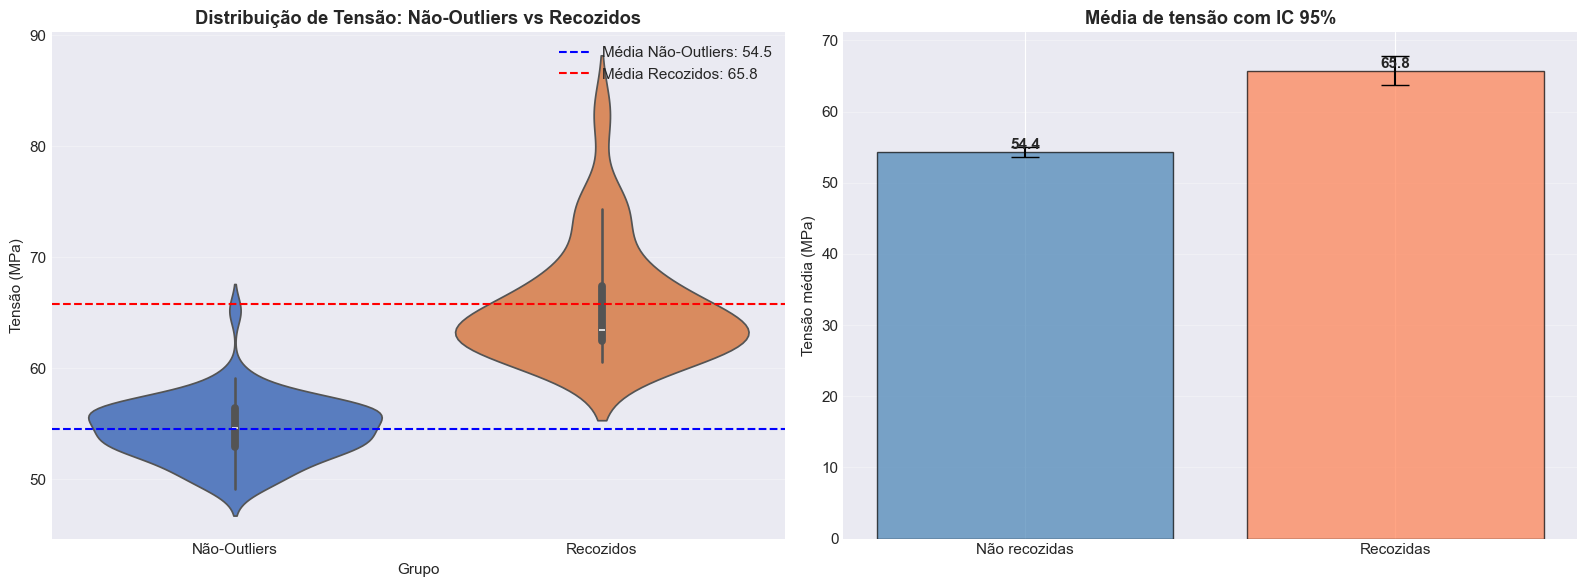

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ordem = ['nao_outlier', 'recozido']
df_comp = df_final[df_final['grupo_final'].isin(ordem)]
m_no, m_rec = df_comp.loc[df_comp.grupo_final == 'nao_outlier', 'tensao_MPa'].mean(), df_comp.loc[df_comp.grupo_final == 'recozido', 'tensao_MPa'].mean()

#  Violin plot em TENSÃO; 'hue' atribuído e legend=False (palette sem hue é descontinuado no seaborn ≥0.13).
sns.violinplot(data=df_comp, x='grupo_final', y='tensao_MPa', order=ordem, hue='grupo_final', hue_order=ordem,
               palette='muted', legend=False, ax=axes[0])
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(['Não-Outliers', 'Recozidos'])
axes[0].axhline(m_no, color='blue', linestyle='--', label=f'Média Não-Outliers: {m_no:.1f}')
axes[0].axhline(m_rec, color='red', linestyle='--', label=f'Média Recozidos: {m_rec:.1f}')
axes[0].set_title('Distribuição de Tensão: Não-Outliers vs Recozidos', fontweight='bold')
axes[0].set_xlabel('Grupo'); axes[0].set_ylabel('Tensão (MPa)'); axes[0].legend(loc='upper right'); axes[0].grid(axis='y', alpha=0.3)

#  Barras de média com IC 95% (em vez de erro padrão): o IC é o que o texto interpreta ("com 95% de confiança...").
ics = [intervalo_confianca_95(nr_todas['tensao_MPa']), intervalo_confianca_95(rec['tensao_MPa'])]
medias = [nr_todas['tensao_MPa'].mean(), rec['tensao_MPa'].mean()]
erros = [[m - lo for m, (lo, hi) in zip(medias, ics)], [hi - m for m, (lo, hi) in zip(medias, ics)]]
axes[1].bar(['Não recozidas', 'Recozidas'], medias, yerr=erros, capsize=10, color=['steelblue', 'coral'], alpha=0.7, edgecolor='black')
axes[1].set_title('Média de tensão com IC 95%', fontweight='bold'); axes[1].set_ylabel('Tensão média (MPa)'); axes[1].grid(axis='y', alpha=0.3)
for i, m in enumerate(medias): axes[1].text(i, m, f'{m:.1f}', ha='center', va='bottom', fontweight='bold')
plt.tight_layout(); plt.show()

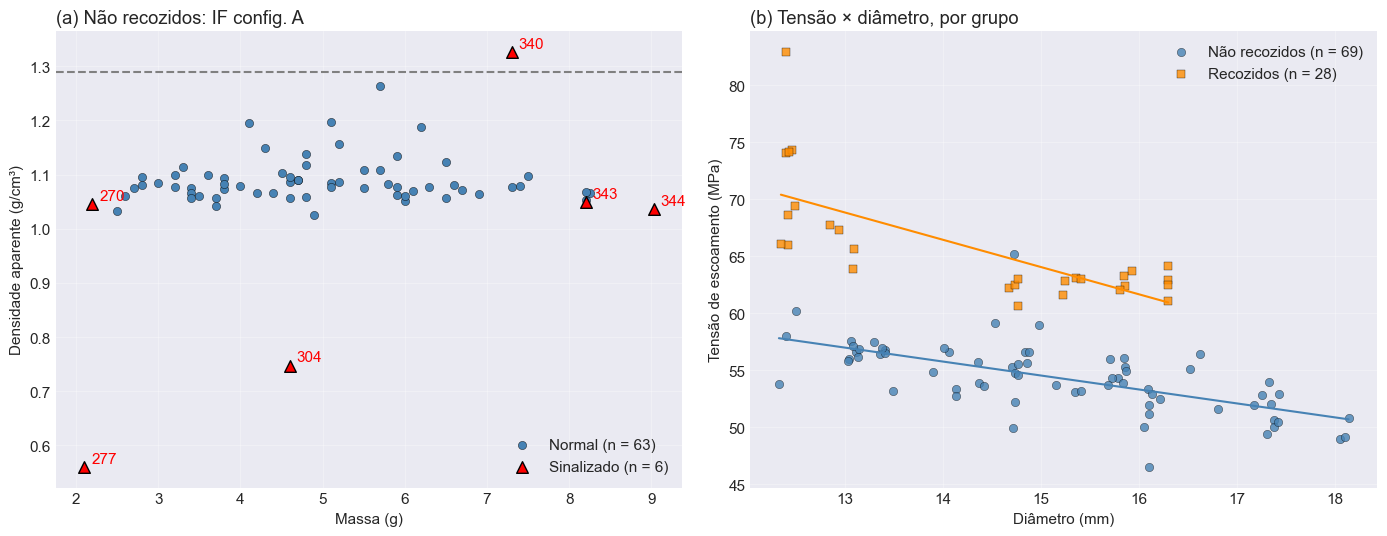

In [45]:
#  Figuras 1a e 1b do artigo: (a) densidade × massa com sinalizados; (b) tensão × diâmetro por grupo com ajuste linear.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
a0 = axes[0]
nor = df_nao_recozidas[df_nao_recozidas['anomalia_A'] == 1]; sin = df_nao_recozidas[df_nao_recozidas['anomalia_A'] == -1]
a0.scatter(nor['massa'], nor['densidade_gcm3'], s=35, c='steelblue', edgecolor='k', linewidth=0.3, label=f'Normal (n = {len(nor)})')
a0.scatter(sin['massa'], sin['densidade_gcm3'], s=70, c='red', marker='^', edgecolor='k', label=f'Sinalizado (n = {len(sin)})')
for _, r in sin.iterrows(): a0.annotate(int(r['ID']), (r['massa'], r['densidade_gcm3']), xytext=(5, 3), textcoords='offset points', color='red')
a0.axhline(RHO_PLA_INJETADO, color='gray', ls='--'); a0.set_xlabel('Massa (g)'); a0.set_ylabel('Densidade aparente (g/cm³)')
a0.set_title('(a) Não recozidos: IF config. A', loc='left'); a0.legend(loc='lower right'); a0.grid(alpha=0.3)

a1 = axes[1]
for g, cor, mk, nome in [(0, 'steelblue', 'o', 'Não recozidos'), (1, 'darkorange', 's', 'Recozidos')]:
    s = df_validos[df_validos['recozimento'] == g]
    a1.scatter(s['diametro'], s['tensao_MPa'], c=cor, marker=mk, edgecolor='k', linewidth=0.3, alpha=0.8, label=f'{nome} (n = {len(s)})')
    p = np.polyfit(s['diametro'], s['tensao_MPa'], 1); xs = np.linspace(s['diametro'].min(), s['diametro'].max(), 20)
    a1.plot(xs, np.polyval(p, xs), color=cor, lw=1.5)
a1.set_xlabel('Diâmetro (mm)'); a1.set_ylabel('Tensão de escoamento (MPa)'); a1.set_title('(b) Tensão × diâmetro, por grupo', loc='left')
a1.legend(); a1.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Validação externa (opcional): só se a lista de amostras anômalas conhecidas for disponibilizada

In [46]:
# Verificação externa OPCIONAL. Hoje não existe gabarito (a informação de fabricação não foi disponibilizada), por isso a confiança
# vem do bootstrap acima. Se um dia a lista de amostras anômalas reais for informada, preencha abaixo para calcular sensibilidade e
# precisão. Como o IF é não supervisionado, esses rótulos NÃO entram no treino; servem apenas de conferência.
AMOSTRAS_ANOMALAS_CONHECIDAS = []   # ex.: [281, 295, 302]

def validar_com_gabarito(anomalas, df_g=None, nome='não recozidas'):
    df_g = df_nao_recozidas if df_g is None else df_g
    anomalas = set(anomalas); universo = set(df_g['ID'])
    for cfg, col in [('A (não destrutiva)', 'anomalia_A'), ('B (com força)', 'anomalia_B')]:
        sinal = set(df_g.loc[df_g[col] == -1, 'ID'])
        vp = anomalas & sinal; fn = (anomalas & universo) - sinal; fp = sinal - anomalas
        print(f"[{nome}] Config. {cfg}: detectadas {len(vp)}/{len(anomalas & universo)} {sorted(vp)} | não detectadas {sorted(fn)} | falsos positivos {len(fp)} {sorted(fp)}")
        if anomalas & universo: print(f"   sensibilidade = {len(vp)/len(anomalas & universo):.0%} | precisão = {len(vp)/max(1, len(sinal)):.0%}")
    fora = sorted(anomalas - universo)
    if fora: print(f"Atenção: IDs fora do universo ensaiado válido: {fora}")

if AMOSTRAS_ANOMALAS_CONHECIDAS: validar_com_gabarito(AMOSTRAS_ANOMALAS_CONHECIDAS)
else: print("Sem gabarito: a confiança das amostras anômalas foi avaliada por bootstrap (seção anterior).")

Sem gabarito: a confiança das amostras anômalas foi avaliada por bootstrap (seção anterior).


# Exportação dos Resultados

In [47]:
# Mantidos os mesmos arquivos e colunas de antes (compatibilidade com scripts/figuras anteriores), com colunas novas ao final.
df_final['suspeito'] = (df_final['grupo_final'] == 'outlier').astype(int)
ids_suspeitos = df_final.loc[df_final['suspeito'] == 1, 'ID']
print("=" * 80); print("IDs SUSPEITOS (OUTLIERS, config. B)"); print("=" * 80)
print(f"Total: {len(ids_suspeitos)}"); print(sorted(ids_suspeitos.tolist()))

# [NOVO] 'suspeito_A' e 'suspeito_B' por grupo (inclui recozidas), pois o detector agora roda nos dois grupos.
df_final['suspeito_A'] = (df_final['anomalia_A'] == -1).astype(int)
df_final['suspeito_B'] = ((df_final['anomalia'] == -1) | (df_final.get('anomalia_B', 1) == -1)).astype(int)

IDs SUSPEITOS (OUTLIERS, config. B)
Total: 6
[270, 272, 277, 304, 340, 344]


In [51]:
df_final[df_final['suspeito'] == 1][['ID', 'massa', 'resistencia', 'grupo_final']].to_csv("IDs_Suspeitos_2025.csv", index=False)
print("✓ Arquivo 'IDs_Suspeitos_2025.csv' salvo com sucesso!")

# Arquivo adicional com as duas configurações, os dois grupos e a tensão: é o que a Tabela 1 do artigo usa.
cols_novas = ['ID', 'recozimento', 'diametro', 'altura', 'massa', 'densidade_gcm3', 'resistencia', 'forca_N', 'tensao_MPa',
              'densidade_implausivel', 'suspeito_A', 'suspeito_B', 'boot_A_pct', 'boot_B_pct', 'classe_A', 'classe_B']
df_final[cols_novas].sort_values('ID').to_csv("Suspeitos_ConfigA_ConfigB_2025.csv", index=False)
print("✓ Arquivo 'Suspeitos_ConfigA_ConfigB_2025.csv' salvo com sucesso!")

#  Arquivo equivalente ao 'Analise_Estabilidade_Outliers24.csv' do CBECIMAT, para a base 2025 (todas as amostras válidas).
df_final[['ID', 'recozimento', 'massa', 'densidade_gcm3', 'suspeito_A', 'suspeito_B', 'boot_A_pct', 'boot_B_pct', 'classe_A', 'classe_B']] \
    .sort_values('ID').to_csv("Estabilidade_Bootstrap_2025.csv", index=False)
print("✓ Arquivo 'Estabilidade_Bootstrap_2025.csv' salvo com sucesso!")

df_final.to_csv("Analise_Completa_2025.csv", index=False)
print("✓ Arquivo 'Analise_Completa_2025.csv' salvo com sucesso!")

✓ Arquivo 'IDs_Suspeitos_2025.csv' salvo com sucesso!
✓ Arquivo 'Suspeitos_ConfigA_ConfigB_2025.csv' salvo com sucesso!
✓ Arquivo 'Estabilidade_Bootstrap_2025.csv' salvo com sucesso!
✓ Arquivo 'Analise_Completa_2025.csv' salvo com sucesso!


# Resumo dos Resultados

In [ ]:
#  Esta célula antes reconvertia colunas e recalculava médias/testes por conta própria (duplicando a lógica, e com
# Welch aqui e Student lá, o que gerava p-valores diferentes para a "mesma" comparação). Agora apenas resume o que as
# funções acima já calcularam: uma única fonte de verdade.
print("=" * 80); print("RESUMO"); print("=" * 80)
print(f"Amostras: {len(df)} | falhas: {int(df['falha_ensaio'].sum())} | válidas: {len(df_validos)} "
      f"({len(df_nao_recozidas)} não recozidas + {len(df_recozidas)} recozidas)")
print(f"Sinalizados (não recozidas) | A: {ids(df_nao_recozidas, 'anomalia_A')} | B: {ids(df_nao_recozidas, 'anomalia')}")
for k, r in res.items():
    print(f"{r['nome'][:58]:58s} dif = {r['pct']:+6.2f}% | Welch p = {r['p_welch']:.4g} | MW p = {r['p_mw']:.4g} | g = {r['g']:.2f}")
for g, df_g in [('Não recozidas', df_nao_recozidas), ('Recozidas', df_recozidas)]:
    print(f"{g} (config. A): " + ", ".join(f"{int(r.ID)} ({r.boot_A_pct:.0f}%, {r.classe_A})" for r in df_g[df_g['anomalia_A'] == -1].sort_values('boot_A_pct', ascending=False).itertuples()))
print("\nLeitura: em força o ganho não é significativo; em tensão (MPa) é grande e significativo, e permanece ao ajustar pelo diâmetro.")

RESUMO
Amostras: 107 | falhas: 10 | válidas: 97 (69 não recozidas + 28 recozidas)
Sinalizados (não recozidas) | A: [270, 277, 304, 340, 343, 344] | B: [270, 272, 277, 304, 340, 344]
FORÇA: não-outliers (B) vs recozidos                       dif =  +6.69% | Welch p = 0.1018 | MW p = 0.09442 | g = 0.39
FORÇA: todas as não recozidas vs recozidas                 dif =  +7.31% | Welch p = 0.07634 | MW p = 0.07389 | g = 0.41
TENSÃO: todas as não recozidas vs recozidas                dif = +20.96% | Welch p = 7.733e-13 | MW p = 4.315e-14 | g = 3.02
TENSÃO: sem sinalizados (config. A) nos dois grupos        dif = +18.84% | Welch p = 1.255e-14 | MW p = 9.777e-13 | g = 3.43
Não recozidas (config. A): 277 (96%, robusta), 344 (96%, robusta), 340 (89%, fronteira), 270 (80%, fronteira), 304 (68%, fronteira), 343 (52%, fronteira)
Recozidas (config. A): 408 (66%, fronteira), 400 (64%, fronteira), 431 (56%, fronteira)

Leitura: em força o ganho não é significativo; em tensão (MPa) é grande e significat